# Analyze Visium H&E data

### Aim: 
analyse gene expression with tissue location and the H&E imgae

### Data:
mouse coronal brain slice that is preprocessed and clustered with names by brain region

### Workflow:
1. Load the data and image and plot clusters on the tissue
2. Extract image features from the H&E and cluster spots by appearance
3. Neighbourhood enrichment: which clusters sit next to each other?
4. Co-occurrence: how does that change with distance?
5. Ligand-receptor analysis: which signals might clusters send each other? 
6. Moran's I: which genes from spatial patterns?

In [1]:
import numpy as np
import pandas as pd

import anndata as ad
import scanpy as sc
import squidpy as sq

sc.logging.print_header()
print(f"squidpy=={sq.__version__}")

# load the pre-processed dataset
img = sq.datasets.visium_hne_image()
adata = sq.datasets.visium_hne_adata()

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


squidpy==1.8.3


/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


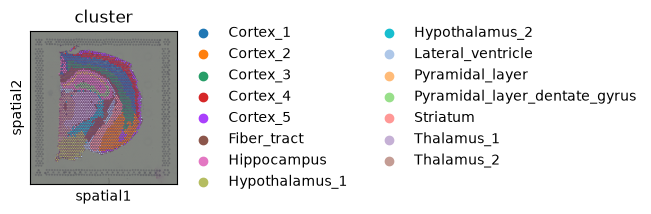

In [2]:
# visualize alredy clustered data with anotation
sq.pl.spatial_scatter(adata, color="cluster")

In [3]:
# calculate features for different scales (higher value means more context)
for scale in [1.0, 2.0]:
    feature_name = f"features_summary_scale{scale}"
    sq.im.calculate_image_features(
        adata,
        img.compute(),
        features="summary",
        key_added=feature_name,
        n_jobs=4,
        scale=scale,
    )
# each scale version will hold 5 values for each colour
# quantile-0.1 for darkest 10% of the image
# quantile-0.5 for the median value of the image
# quantile-0.9 for the lightest 10% of the image
# mean for the average value of the image
# std for the standard deviation of the image
# and each scale has this 5 values per colour channel RGB (ch-0, ch-1, ch-2) so in total 15 features per scale

# combine features in one dataframe
# some column name like summary_ch-0_mean is same for both scales so scale 2.0 version with be renamed to summary_ch-0_mean-1
adata.obsm["features"] = pd.concat(
    [adata.obsm[f] for f in adata.obsm.keys() if "features_summary" in f],
    axis="columns",
)
# make sure that we have no duplicated feature names in the combined table
adata.obsm["features"].columns = ad.utils.make_index_unique(
    adata.obsm["features"].columns
)

100%|██████████| 2688/2688 [00:14<00:00, 187.48/s]


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_57790/3159759931.py:21: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packag

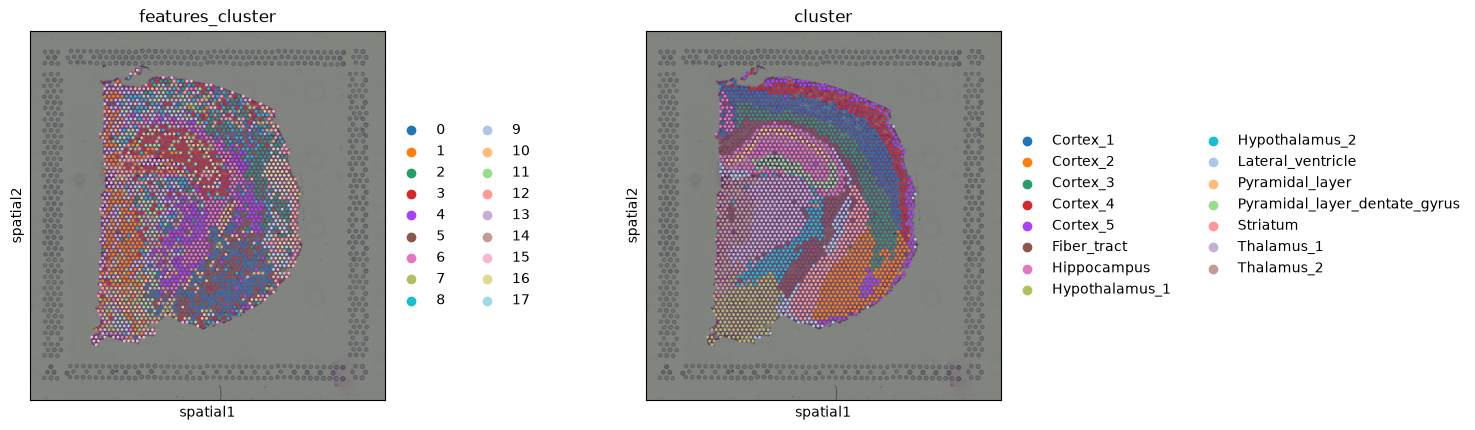

In [4]:
# helper function returning a clustering
# scale -> PCA -> neighbours -> leiden clustering
def cluster_features(features: pd.DataFrame, like=None) -> pd.Series:
    """
    Calculate leiden clustering of features.

    Specify filter of features using `like`.
    """
    # filter features
    if like is not None:
        features = features.filter(like=like)
    # create temporary adata to calculate the clustering
    adata = ad.AnnData(features)
    # important - feature values are not scaled, so need to scale them before PCA
    # z-socre each column mean=0, std=1
    sc.pp.scale(adata)
    # calculate leiden clustering
    # features.shape[1] is 30 and pca capped at 10 for the safety limit
    sc.pp.pca(adata, n_comps=min(10, features.shape[1] - 1))
    sc.pp.neighbors(adata)
    sc.tl.leiden(adata)

    return adata.obs["leiden"]


# calculate feature clusters
adata.obs["features_cluster"] = cluster_features(adata.obsm["features"], like="summary")

# compare feature and gene clusters
# clusters from the image and clusters from the genes
# information from genes shows layers but not image
    # several clusters parallel to each other in the gene clusters but not in the image clusters
sq.pl.spatial_scatter(adata, color=["features_cluster", "cluster"])

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_57790/2792069497.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)
100%|██████████| 1000/1000 [00:02<00:00, 348.06/s]


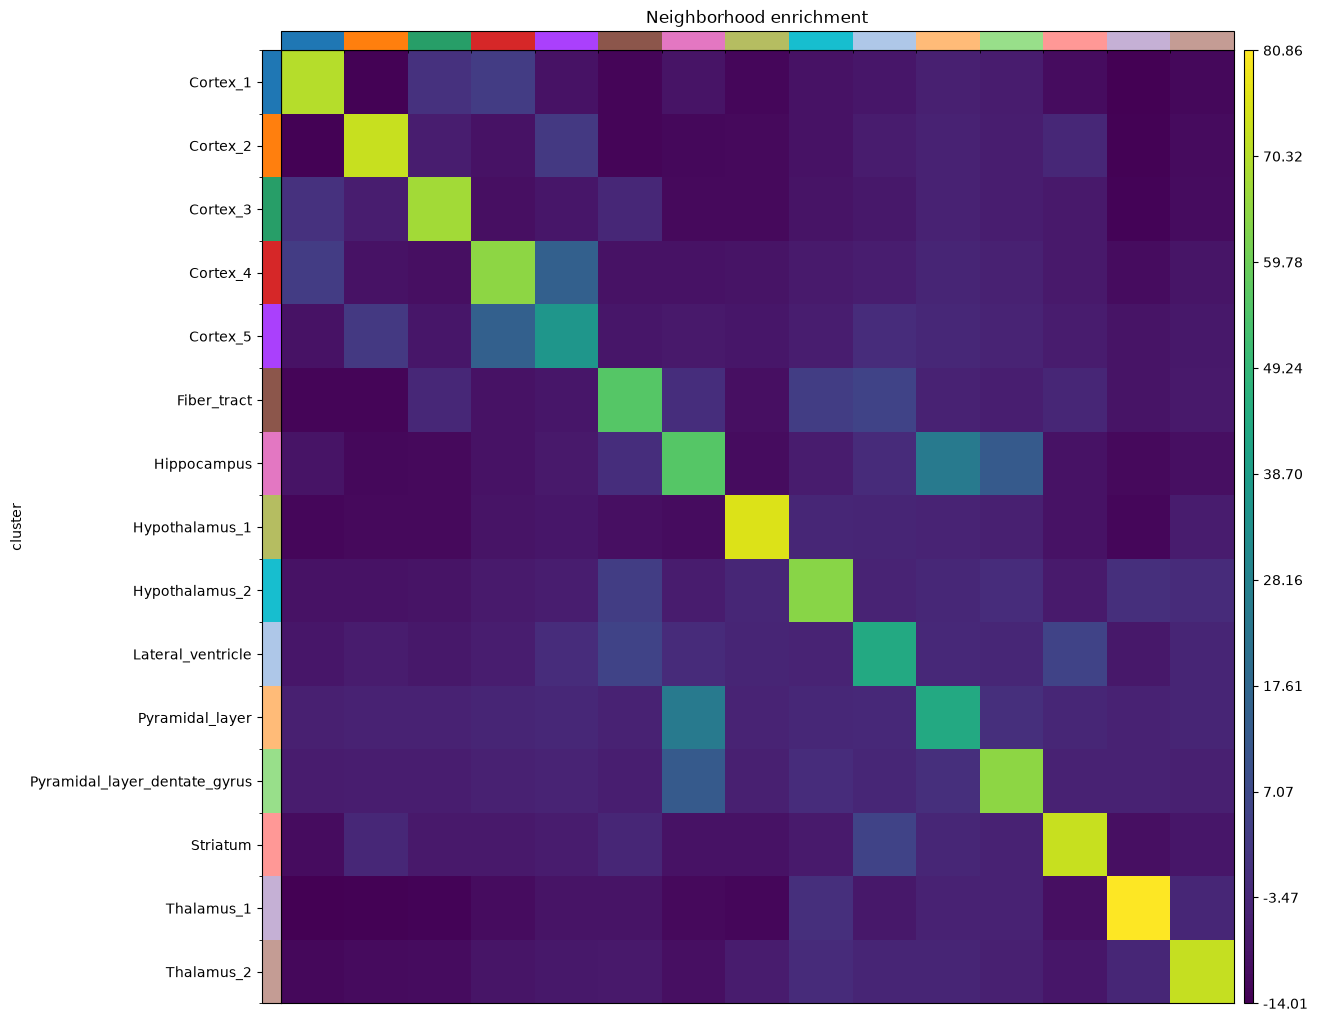

In [5]:
# neighbourhood enrichment identifies which clusters are more likely to be neighbours than expected by chance
sq.gr.spatial_neighbors(adata)
# gr.spatial_neighbors() for spots touching each other, pp.neighbors() for spots look alike in their genes
sq.gr.nhood_enrichment(adata, cluster_key="cluster")
sq.pl.nhood_enrichment(adata, cluster_key="cluster")

# this can be applied in tumour microenvironment for CD8 T cells and tumour cells to see if they are neighbours or not

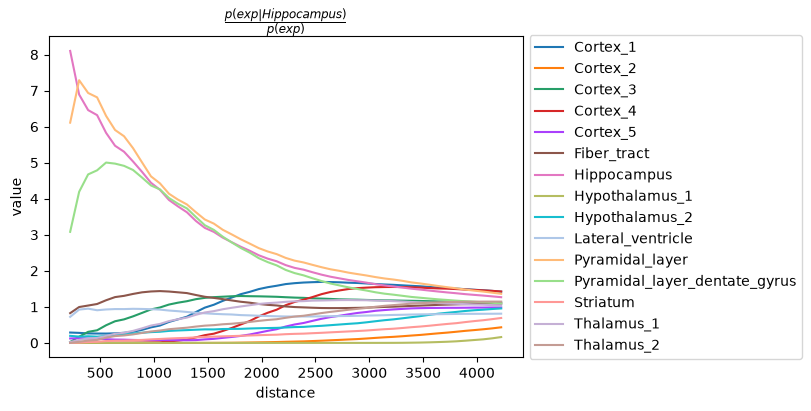

In [6]:
# co-occurrence: how much more (or less) often a cluster is found within a given distance
# of another cluster than expected by chance, calculated at increasing distances
# score = (share of Pyramidal_layer inside the circles around Hippocampus spots) / (share of Pyramidal_layer overall)
# if the socre is above 1, cluster A and B co-occur and found together in the same image
# if the score is around 1 -> no relationship and score below 1 not found together in the same image
sq.gr.co_occurrence(adata, cluster_key="cluster")
sq.pl.co_occurrence(
    adata,
    cluster_key="cluster",
    clusters="Hippocampus",
    figsize=(8, 4),
)

# distance here is in pixels not micrometers

18.3MB [00:00, 36.3MB/s]
1.78MB [00:00, 60.0MB/s]
4.27MB [00:00, 45.1MB/s]
100%|██████████| 100/100 [00:11<00:00,  8.51permutation/s]
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_ligrec.py:248: FutureWarning: The method uns_keys is deprecated and will be removed in the future. Use uns instead of uns_keys. (e.g. `k in adata.uns` or `sorted(adata.uns)`)
  if cluster_key not in adata.uns_keys():
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_ligrec.py:36: UserWarning: Over 500 categories found. Plot would be very large.
  super().__init__(*args, **kwargs)




In [ ]:
# ligand-receptor analysis identifies which ligands and receptors are expressed in different clusters
sq.gr.ligrec(
    adata,
    n_perms=100,
    cluster_key="cluster",
)
sq.pl.ligrec(
    adata,
    cluster_key="cluster",
    source_groups="Hippocampus", # cluster with ligand
    target_groups=["Pyramidal_layer", "Pyramidal_layer_dentate_gyrus"], # receptor
    means_range=(3, np.inf), # show pairs with min 3 expression of ligand and receptor
    alpha=1e-4, # p < 0.0001
    swap_axes=True,
)

## genes with a spatial pattern (Moran's I)
Moran's I statistics measure if the neighbouring spots have similar gene expression values. Moran's I: one score per gene summarising, across all neighbouring spot pairs, whether neighbours have similar expression (I near 1 = spatial pattern, near 0 = random) In this tutorial across all 2,688 spots, they used 6 touching neighbours of every spot from the spatial graph. 


calculation example:
Gene A high on one side and low on the other
|values | 1| 1| 1| 9| 9| 9| average = 5|
|---|---|---|---|---|---|---|---|
|differences|-4|-4|-4|+4|+4|+4| |

----
|neighbour pair | product|
|---|---|
|spot 1-2| -4 x -4 = 16|
|spot 2-3| -4 x -4 = 16|
|spot 3-4| -4 x 4 = -16|
|spot 4-5| 4 x 4 = 16|
|spot 5-6| 4 x 4 = 16|

Therefore 
average = (16 +16 - 16 + 16 + 16)/ 5 pairs = 48 / 5 = 9.6
variance = average of squared differences from the mean
4^2 or -4^2 = 16

Moran's I = 9.6 / 16 = 0.6


In [ ]:
genes = adata[:, adata.var.highly_variable].var_names.values[:1000]
sq.gr.spatial_autocorr(
    adata,
    mode="moran",
    genes=genes,
    n_perms=100,
    n_jobs=1,
)

100%|██████████| 100/100 [01:24<00:00,  1.19/s]


In [9]:
adata.uns["moranI"].head(10)

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
Olfm1,0.763291,0.0,0.000131,0.0,0.009901,0.000257,0.0,0.0,0.011745
Plp1,0.747660,0.0,0.000131,0.0,0.009901,0.000310,0.0,0.0,0.011745
Itpka,0.727076,0.0,0.000131,0.0,0.009901,0.000270,0.0,0.0,0.011745
Snap25,0.720987,0.0,0.000131,0.0,0.009901,0.000317,0.0,0.0,0.011745
Nnat,0.708637,0.0,0.000131,0.0,0.009901,0.000232,0.0,0.0,0.011745
Ppp3ca,0.693320,0.0,0.000131,0.0,0.009901,0.000287,0.0,0.0,0.011745
Chn1,0.684957,0.0,0.000131,0.0,0.009901,0.000273,0.0,0.0,0.011745
Mal,0.679775,0.0,0.000131,0.0,0.009901,0.000277,0.0,0.0,0.011745
Tmsb4x,0.676719,0.0,0.000131,0.0,0.009901,0.000211,0.0,0.0,0.011745
Cldn11,0.674110,0.0,0.000131,0.0,0.009901,0.000297,0.0,0.0,0.011745


/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


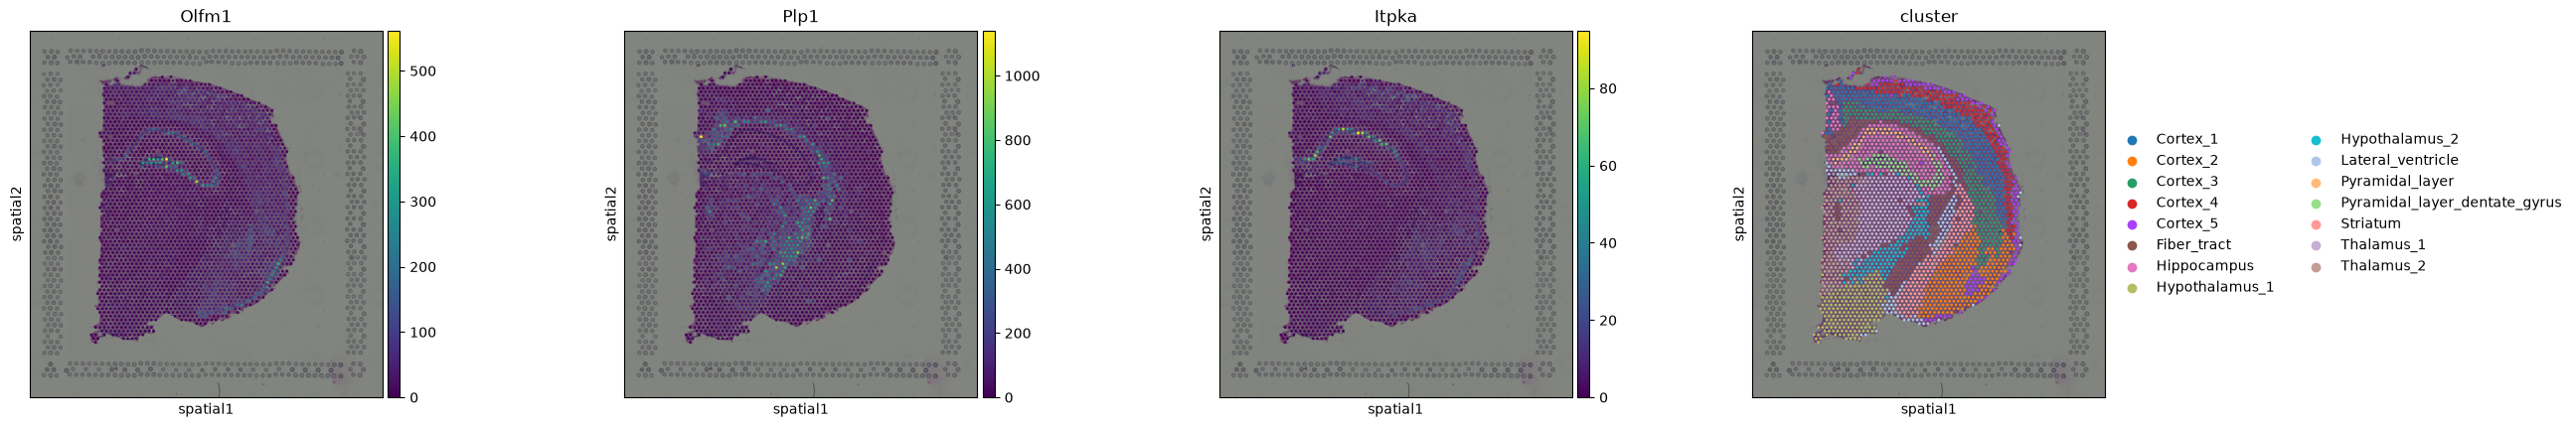

In [10]:
sq.pl.spatial_scatter(adata, color=["Olfm1", "Plp1", "Itpka", "cluster"])